# Синтез многоплоскостных фазовых голограмм

*В данном ноутбуке представлена техническая реализация решения задачи по фотонике, исследованной на хакатоне вместе с моими коллегами. Рассматривается формирование четырёх изображений одной фазовой маской.*

Основной **целью** было сравнить классический алгоритм, прямую оптимизацию фазы и заранее обученную физическую сеть на одинаковых входных изображениях.

Так же **дополнительной задачей** была проверка практической схемы: сеть быстро формирует начальную маску, после чего физическая оптимизация уточняет её под текущую четвёрку.

### **1. Инициализация и Физическая модель**

Входом служат четыре полутоновых изображения размером $128\times128$. Выход — одна фазовая маска, которая при распространении света формирует приближённые изображения на четырёх расстояниях.

- **Single-FFT Fresnel:** прямое распространение на расстояния 24.1, 25.3, 26.5 и 27.7 мм; длина волны 532 нм, шаг пикселя маски 10 мкм.
- **Natural Output Grid (естественная выходная сетка):** шаг пикселя экрана зависит от расстояния: $\Delta x'=\lambda z/(N\Delta x)$. Сравнение выполняется в индексах исходного оценщика команды, без дополнительной интерполяции.
- **Amplitude Normalization (нормировка амплитуды):** яркость для метрик определяется как $|U|/\max|U|$ отдельно для каждой плоскости. Это соглашение используемого оценщика; физическая интенсивность пропорциональна $|U|^2$.

Все методы оцениваются после сохранения и повторного чтения 8-битной фазовой маски и изображений восстановления. Прямой расчёт дополнительно проверяется независимой реализацией NumPy.

In [1]:
# @title Подготовка библиотек
import importlib.util
import subprocess
import sys
required = {'torch':'torch', 'numpy':'numpy', 'pandas':'pandas',
            'matplotlib':'matplotlib', 'seaborn':'seaborn', 'PIL':'Pillow'}
missing = [package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
import os, io, json, math, time, hashlib, zipfile, platform
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image as PILImage
from IPython.display import display, Image as DisplayImage, FileLink, Markdown
import torch
from torch import nn
import torch.nn.functional as F
torch.set_num_threads(min(4, os.cpu_count() or 1))

In [2]:
import csv
import hashlib
import json
import math
import time
from dataclasses import dataclass, asdict
from pathlib import Path
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F

Z_MM = (24.1, 25.3, 26.5, 27.7)

def sync(device):
    if torch.device(device).type == 'cuda': torch.cuda.synchronize(device)
    elif torch.device(device).type == 'mps': torch.mps.synchronize()

def seed_all(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

class Fresnel(nn.Module):
    """Single-FFT operator on the four natural output grids, matching the team evaluator.
    Output-only unit-modulus factors and positive scale factors cancel in amplitude/max.
    No padding, cropping, interpolation or substitution by ASM.
    """
    def __init__(self, n=128, dx=10e-6, wavelength=532e-9,
                 z_mm=Z_MM, dtype=torch.float32):
        super().__init__()
        self.n, self.dx, self.wavelength = n, dx, wavelength
        self.z_mm = tuple(z_mm)
        c = (torch.arange(n, dtype=torch.float64) - n//2)*dx
        yy, xx = torch.meshgrid(c, c, indexing='ij')
        ch = torch.stack([torch.exp(1j*math.pi/(wavelength*z*1e-3)*(xx**2+yy**2)) for z in z_mm])
        cd = torch.complex128 if dtype == torch.float64 else torch.complex64
        self.register_buffer('chirp', ch.to(cd))

    @staticmethod
    def fft(x):
        return torch.fft.fftshift(torch.fft.fft2(torch.fft.ifftshift(x, dim=(-2,-1)), norm='ortho'), dim=(-2,-1))

    @staticmethod
    def ifft(x):
        return torch.fft.fftshift(torch.fft.ifft2(torch.fft.ifftshift(x, dim=(-2,-1)), norm='ortho'), dim=(-2,-1))

    def field(self, u):
        return self.fft(u.unsqueeze(-3)*self.chirp)

    def forward(self, phi):
        return self.field(torch.exp(1j*phi))

    def adjoint_planes(self, fields):
        return self.ifft(fields)*self.chirp.conj()

    def adjoint(self, fields):
        return self.adjoint_planes(fields).sum(-3)

    def output_pitch_um(self):
        return [self.wavelength*z*1e-3/(self.n*self.dx)*1e6 for z in self.z_mm]

def image_from_field(field):
    # Smooth modulus only at exact zero; no singular gradients there.
    amp = torch.sqrt(field.real.square()+field.imag.square()+1e-12)
    return amp/amp.amax((-2,-1), keepdim=True).clamp_min(1e-8)

def pcc(a,b):
    a=a-a.mean((-2,-1),keepdim=True); b=b-b.mean((-2,-1),keepdim=True)
    den=torch.sqrt((a*a).sum((-2,-1))*(b*b).sum((-2,-1))+1e-12)
    return (a*b).sum((-2,-1))/den

def local_ssim(a,b):
    """Gaussian 11x11, sigma 1.5, valid area, population covariance, data_range=1."""
    n=a.shape[-1]; prefix=a.shape[:-2]
    x=a.reshape(-1,1,n,n); y=b.reshape(-1,1,n,n)
    k=min(11, n if n%2 else n-1)
    g=torch.arange(k,device=a.device,dtype=a.dtype)-(k-1)/2
    g=torch.exp(-g.square()/(2*1.5**2)); g=g/g.sum()
    w=(g[:,None]*g[None,:])[None,None]
    # One grouped convolution for all five statistics.
    stats=F.conv2d(torch.cat([x,y,x*x,y*y,x*y],1),w.repeat(5,1,1,1),groups=5)
    mx,my,exx,eyy,exy=stats.split(1,1)
    vx=exx-mx*mx; vy=eyy-my*my; cov=exy-mx*my
    s=((2*mx*my+0.01**2)*(2*cov+0.03**2))/((mx*mx+my*my+0.01**2)*(vx+vy+0.03**2))
    return s.mean((1,2,3)).reshape(prefix)

def phase_codes(phi):
    return torch.round(torch.remainder(phi+math.pi,2*math.pi)/(2*math.pi)*255).clamp(0,255).to(torch.uint8)

def decode_phase(codes):
    return codes.to(torch.float32)/255*(2*math.pi)-math.pi

def score_arrays(pred, target):
    p=pcc(pred,target); s=local_ssim(pred,target)
    return {'pcc':float(p.mean()),'ssim':float(s.mean()),'pcc_min':float(p.min()),
            'ssim_min':float(s.min()),'pcc_planes':p.tolist(),'ssim_planes':s.tolist(),
            'selection_score':float((p.mean()+s.mean())/2)}

def evaluate(phi, target, physics):
    ph=decode_phase(phase_codes(phi)).to(phi.device)
    rec=torch.round(image_from_field(physics(ph))*255)/255
    return score_arrays(rec,target),rec

def objective(phi,target,physics,ssim_weight=1.0,worst_weight=0.0):
    rec=image_from_field(physics(phi))
    err=(1-pcc(rec,target))+ssim_weight*(1-local_ssim(rec,target))
    return err.mean()+worst_weight*err.max()

def start_phase(n, seed, kind, device):
    # Local generator: diagnostic ground-truth seeds cannot leak into starts.
    gen=torch.Generator(device='cpu').manual_seed(seed)
    if kind=='random':
        return (torch.rand(n,n,generator=gen)*2*math.pi-math.pi).to(device)
    if kind=='smooth':
        small=torch.randn(1,1,8,8,generator=gen)
        p=F.interpolate(small,size=(n,n),mode='bicubic',align_corners=False)[0,0]
        return (0.35*p/p.std().clamp_min(1e-8)).to(device)
    raise ValueError(kind)

def numpy_reconstruct(codes,physics):
    phase=np.asarray(codes,dtype=np.float64)/255*(2*np.pi)-np.pi
    n=phase.shape[-1];c=(np.arange(n)-n//2)*physics.dx
    yy,xx=np.meshgrid(c,c,indexing='ij');out=[]
    for z in physics.z_mm:
        ch=np.exp(1j*np.pi/(physics.wavelength*z*1e-3)*(xx*xx+yy*yy))
        u=np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(np.exp(1j*phase)*ch),norm='ortho'))
        a=np.abs(u);out.append(a/a.max())
    return np.stack(out)

def verify_physics():
    """Independent numerical checks, not tests that just repeat implementation."""
    seed_all(9501);f=Fresnel(n=16,dtype=torch.float64)
    u=torch.randn(16,16,dtype=torch.complex128)
    v=torch.randn(4,16,16,dtype=torch.complex128)
    a=(f.field(u).conj()*v).sum();b=(u.conj()*f.adjoint(v)).sum()
    adj=float((a-b).abs()/(a.abs()+b.abs()).clamp_min(1e-12))
    roundtrip=float((f.adjoint_planes(f.field(u))-u).norm()/u.norm())
    norm=float(((f.field(u).abs().square().sum((-2,-1))-u.abs().square().sum()).abs()/u.abs().square().sum()).max())
    # Direct DFT sum, independent of any FFT implementation.
    j=torch.arange(16,dtype=torch.float64)-8
    matrix=torch.exp(-2j*math.pi*j[:,None]*j[None,:]/16)/math.sqrt(16)
    direct=torch.stack([matrix@(u*c)@matrix.T for c in f.chirp])
    dft=float((direct-f.field(u)).norm()/direct.norm())
    p=torch.randn(16,16,dtype=torch.float64,requires_grad=True)
    target=torch.rand(4,16,16,dtype=torch.float64)
    loss=objective(p,target,f)
    g=torch.autograd.grad(loss,p)[0]
    direction=torch.randn_like(p);direction/=direction.norm();eps=1e-5
    fd=(objective(p.detach()+eps*direction,target,f)-objective(p.detach()-eps*direction,target,f))/(2*eps)
    gradient_error=float((fd-(g*direction).sum()).abs())
    phase_invariance=float((image_from_field(f(p.detach()))-image_from_field(f(p.detach()+0.731))).abs().max())
    checks={'adjoint_relative_error':adj,'plane_roundtrip_relative_error':roundtrip,
            'energy_relative_error':norm,'fft_vs_direct_sum_relative_error':dft,
            'directional_gradient_absolute_error':gradient_error,'global_phase_invariance_error':phase_invariance}
    assert max(adj,roundtrip,norm,dft,phase_invariance)<1e-10,checks
    assert gradient_error<2e-6,checks
    return checks

In [3]:
class MetricPack(nn.Module):
    """Same SSIM as the team evaluator, with constant target statistics cached."""
    def __init__(self, target):
        super().__init__()
        self.register_buffer('target', target)
        self.register_buffer('centered_target', target-target.mean((-2, -1), keepdim=True))
        self.register_buffer('target_energy', self.centered_target.square().sum((-2, -1)))
        g = torch.arange(11, device=target.device, dtype=target.dtype)-5
        g = torch.exp(-g.square()/(2*1.5**2)); g = g/g.sum()
        self.register_buffer('window', (g[:, None]*g[None, :])[None, None])
        self.register_buffer('windows3', self.window.repeat(3, 1, 1, 1))
        y = target[:, None]
        my = F.conv2d(y, self.window)
        self.register_buffer('my', my)
        self.register_buffer('vy', F.conv2d(y*y, self.window)-my*my)

    def forward(self, rec):
        a = rec-rec.mean((-2, -1), keepdim=True)
        p = (a*self.centered_target).sum((-2, -1))/torch.sqrt(
            a.square().sum((-2, -1))*self.target_energy+1e-12)
        x = rec[:, None]; y = self.target[:, None]
        mx, exx, exy = F.conv2d(torch.cat([x, x*x, x*y], 1), self.windows3, groups=3).split(1, 1)
        vx = exx-mx*mx; cov = exy-mx*self.my
        s = ((2*mx*self.my+0.01**2)*(2*cov+0.03**2))/(
            (mx*mx+self.my*self.my+0.01**2)*(vx+self.vy+0.03**2))
        return p, s.mean((1, 2, 3))

    def loss(self, phi, physics):
        p, s = self(image_from_field(physics(phi)))
        return (1-p).mean()+(1-s).mean()

    @torch.no_grad()
    def evaluate(self, phi, physics):
        codes = phase_codes(phi)
        ph = decode_phase(codes).to(phi.device)
        rec = torch.round(image_from_field(physics(ph))*255)/255
        p, s = self(rec)
        metrics = {'pcc': float(p.mean()), 'ssim': float(s.mean()),
            'pcc_min': float(p.min()), 'ssim_min': float(s.min()),
            'pcc_planes': p.cpu().tolist(), 'ssim_planes': s.cpu().tolist(),
            'selection_score': float((p.mean()+s.mean())/2)}
        return metrics, codes, rec

In [4]:
class SingleFFTFresnel(nn.Module):
    def __init__(self, N=128, du=10e-6, wavelength=532e-9, z_list=(24.1e-3, 25.3e-3, 26.5e-3, 27.7e-3)):
        super().__init__()
        self.N = N
        self.du = du
        self.wavelength = wavelength
        self.z_list = list(z_list)
        self.num_planes = len(z_list)

        idx = torch.arange(-N // 2, N // 2, dtype=torch.float64)
        p, q = torch.meshgrid(idx, idx, indexing="ij")
        u2_v2 = (p * du) ** 2 + (q * du) ** 2

        in_chirps, out_chirps, dx_list = [], [], []
        for z in self.z_list:
            k = 2.0 * math.pi / wavelength
            dx = wavelength * z / (N * du)
            dx_list.append(dx)
            x2_y2 = (p * dx) ** 2 + (q * dx) ** 2

            c_in = torch.exp(1j * (math.pi * u2_v2 / (wavelength * z)))
            c_out = torch.exp(1j * ((k * z - math.pi / 2.0) + math.pi * x2_y2 / (wavelength * z)))
            in_chirps.append(c_in)
            out_chirps.append(c_out)

        self.register_buffer("in_chirps", torch.stack(in_chirps, dim=0).to(torch.complex64))
        self.register_buffer("out_chirps", torch.stack(out_chirps, dim=0).to(torch.complex64))
        self.register_buffer("in_chirps_64", torch.stack(in_chirps, dim=0))
        self.register_buffer("out_chirps_64", torch.stack(out_chirps, dim=0))
        self.dx_list = dx_list

    def forward(self, u0: torch.Tensor, use_double: bool = False) -> torch.Tensor:
        c_in = self.in_chirps_64 if use_double else self.in_chirps
        c_out = self.out_chirps_64 if use_double else self.out_chirps
        u_exp = u0.unsqueeze(-3) * c_in
        u_sh = torch.fft.ifftshift(u_exp, dim=(-2, -1))
        spec = torch.fft.fft2(u_sh, dim=(-2, -1), norm="ortho")
        spec_c = torch.fft.fftshift(spec, dim=(-2, -1))
        return spec_c * c_out

    def adjoint(self, kz: torch.Tensor, use_double: bool = False) -> torch.Tensor:
        c_in = self.in_chirps_64 if use_double else self.in_chirps
        c_out = self.out_chirps_64 if use_double else self.out_chirps
        w = kz * torch.conj(c_out)
        w_sh = torch.fft.ifftshift(w, dim=(-2, -1))
        u_back = torch.fft.ifft2(w_sh, dim=(-2, -1), norm="ortho")
        u_c = torch.fft.fftshift(u_back, dim=(-2, -1))
        return u_c * torch.conj(c_in)

class PhaseQuantizeSTE( torch.autograd.Function ):
    """
    Straight-Through Estimator для 8-битного сохранения фазы в PNG:
    Прямой проход: φ in [-π, π] -> q = round((φ + π)/(2π)*255) -> φ_q = q/255*2π - π.
    Обратный проход: единичный якобиан.
    """
    @staticmethod
    def forward(ctx, phi: torch.Tensor) -> torch.Tensor:
        # Приводим фазу к [-π, π)
        phi_wrapped = torch.atan2(torch.sin(phi), torch.cos(phi))
        q = torch.round((phi_wrapped + math.pi) / (2.0 * math.pi) * 255.0).clamp(0.0, 255.0)
        phi_decoded = (q / 255.0) * (2.0 * math.pi) - math.pi
        return phi_decoded

    @staticmethod
    def backward(ctx, grad_output: torch.Tensor) -> torch.Tensor:
        return grad_output

class SpectralConv2d(nn.Module):
    """
    Глобальный спектральный слой (2D Fourier Neural Operator) для обмена фазовой
    информацией по всей апертуре 128x128 за один шаг.
    """
    def __init__(self, in_ch: int, out_ch: int, modes: int = 32):
        super().__init__()
        self.in_ch = in_ch
        self.out_ch = out_ch
        self.modes = modes
        scale = 1.0 / (in_ch * out_ch)
        self.weights1 = nn.Parameter(scale * torch.randn(in_ch, out_ch, modes, modes, dtype=torch.complex64))
        self.weights2 = nn.Parameter(scale * torch.randn(in_ch, out_ch, modes, modes, dtype=torch.complex64))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, C, H, W = x.shape
        x_ft = torch.fft.rfft2(x, norm="ortho")
        out_ft = torch.zeros(B, self.out_ch, H, W // 2 + 1, dtype=torch.complex64, device=x.device)
        m = self.modes
        out_ft[:, :, :m, :m] = torch.einsum("bixy,ioxy->boxy", x_ft[:, :, :m, :m], self.weights1)
        out_ft[:, :, -m:, :m] = torch.einsum("bixy,ioxy->boxy", x_ft[:, :, -m:, :m], self.weights2)
        return torch.fft.irfft2(out_ft, s=(H, W), norm="ortho")

class SpectralSpatialBlock(nn.Module):
    """
    Сочетает глобальную спектральную фильтрацию и локальные антиалиасные свёртки
    с циклическим паддингом (без PixelShuffle, чтобы исключить регулярную сетку).
    """
    def __init__(self, channels: int, modes: int = 32):
        super().__init__()
        self.spec = SpectralConv2d(channels, channels, modes=modes)
        self.local = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, padding_mode="circular"),
            nn.GroupNorm(8, channels),
            nn.GELU(),
            nn.Conv2d(channels, channels, 3, padding=1, padding_mode="circular"),
            nn.GroupNorm(8, channels),
        )
        self.act = nn.GELU()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.act(x + self.spec(x) + self.local(x))

class DUSFN(nn.Module):
    """
    Фиксированный вычислительный граф:
    1) Предсказание начальных фаз 4 целевых плоскостей и аналитический перенос K_z^* на SLM.
    2) K развёрнутых шагов с вычислением точного комплексного градиента Виртингера в плоскостях
       и обновлением фазовой маски через SpectralSpatialBlock.
    """
    def __init__(self, fresnel: SingleFFTFresnel, unroll_steps: int = 6, base_ch: int = 48, modes: int = 32):
        super().__init__()
        self.fresnel = fresnel
        self.unroll_steps = unroll_steps

        # 1. Инициализатор фаз целевых плоскостей по входным нормированным амплитудам [B, 4, H, W]
        self.init_net = nn.Sequential(
            nn.Conv2d(4, base_ch, 3, padding=1, padding_mode="circular"),
            nn.GELU(),
            SpectralSpatialBlock(base_ch, modes=modes),
            SpectralSpatialBlock(base_ch, modes=modes),
            nn.Conv2d(base_ch, 4, 1)
        )
        self.plane_init_weights = nn.Parameter(torch.ones(1, 4, 1, 1))

        # 2. Каскад развёрнутых физических блоков
        self.step_Sizes = nn.Parameter(torch.full((unroll_steps, 1, 4, 1, 1), 0.35))
        self.unroll_blocks = nn.ModuleList([
            nn.Sequential(
                # Вход: [Re(U0), Im(U0), Re(Grad), Im(Grad), phi_curr, mean_residual] = 6 каналов
                nn.Conv2d(6, base_ch, 3, padding=1, padding_mode="circular"),
                nn.GELU(),
                SpectralSpatialBlock(base_ch, modes=modes),
                nn.Conv2d(base_ch, 1, 3, padding=1, padding_mode="circular")
            )
            for _ in range(unroll_steps)
        ])

    def forward(self, targets_norm: torch.Tensor, use_ste_quant: bool = True) -> torch.Tensor:
        # Шаг 0: Предсказание начальных фаз в 4 плоскостях и когерентный обратный перенос на SLM
        phi_planes_0 = math.pi * torch.tanh(self.init_net(targets_norm))
        target_fields_0 = targets_norm * torch.exp(1j * phi_planes_0)
        u0_back = (self.fresnel.adjoint(target_fields_0) * self.plane_init_weights).sum(dim=1)
        phi = torch.angle(u0_back)

        # K развёрнутых физических шагов
        for k in range(self.unroll_steps):
            u0 = torch.exp(1j * phi)
            kz = self.fresnel(u0)  # [B, 4, H, W]
            amp = torch.abs(kz) + 1e-8

            # Аналитическое согласование масштаба (проекция амплитуды на целевую)
            num = (amp * targets_norm).sum(dim=(-2, -1), keepdim=True)
            den = (amp * amp).sum(dim=(-2, -1), keepdim=True) + 1e-8
            alpha = num / den

            # Невязка амплитуд в 4 плоскостях и перенос градиента Виртингера на SLM
            res_amp = alpha * amp - targets_norm
            grad_planes = res_amp * (kz / amp)
            grad_u0 = (self.fresnel.adjoint(grad_planes) * self.step_Sizes[k]).sum(dim=1)

            inp = torch.cat([
                u0.real.unsqueeze(1),
                u0.imag.unsqueeze(1),
                grad_u0.real.unsqueeze(1),
                grad_u0.imag.unsqueeze(1),
                phi.unsqueeze(1) / math.pi,
                res_amp.abs().mean(dim=1, keepdim=True)
            ], dim=1)

            delta_phi = self.unroll_blocks[k](inp).squeeze(1)
            phi = phi + delta_phi
            phi = torch.atan2(torch.sin(phi), torch.cos(phi))

        if use_ste_quant:
            phi = PhaseQuantizeSTE.apply(phi)
        return phi

In [5]:
METHODS = ['GS300', 'GS_Adam', 'DUSFN', 'DUSFN_Adam']
METHOD_LABELS = {'GS300': 'GS ×300', 'GS_Adam': 'GS → Adam',
                 'DUSFN': 'DUSFN', 'DUSFN_Adam': 'DUSFN → Adam'}
METHOD_COLORS = {'GS300': '#7A7A8C', 'GS_Adam': '#3F3F50',
                 'DUSFN': '#E6397A', 'DUSFN_Adam': '#9D2356'}
EXPECTED_CHECKPOINT_SHA256 = '04dd6dd8f657205c3c45ac7b722caee05253e2236b39b39127194c233642ee0a'


def configure_figures():
    from matplotlib import font_manager
    sns.set_theme(style='whitegrid', context='paper', font_scale=1.2)
    font = 'DejaVu Serif'
    try:
        font_manager.findfont('Times New Roman', fallback_to_default=False)
        font = 'Times New Roman'
    except ValueError:
        pass
    plt.rcParams.update({'figure.dpi': 300, 'font.family': 'serif',
                         'font.serif': [font], 'font.size': 10,
                         'pdf.fonttype': 42, 'ps.fonttype': 42})


def publish_figure(fig, name, output, show=True):
    output = Path(output); output.mkdir(parents=True, exist_ok=True)
    fig.savefig(output/f'{name}.png', dpi=300, bbox_inches='tight')
    fig.savefig(output/f'{name}.pdf', bbox_inches='tight')
    # Keep notebook outputs small enough for convenient GitHub rendering.
    preview = io.BytesIO()
    fig.savefig(preview, format='png', dpi=115, bbox_inches='tight')
    plt.close(fig)
    if show:
        display(DisplayImage(data=preview.getvalue()))


def save_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding='utf-8')


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(8*1024*1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def locate_checkpoint():
    candidates = []
    configured = os.environ.get('PHOTONIC_CHECKPOINT')
    if configured:
        candidates.append(Path(configured))
    candidates += [Path('/content/best.pt'), Path.cwd()/'best.pt']
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Поместите best.pt рядом с ноутбуком. В Colab файл выбирается через диалог загрузки.')
    print('[INFO] Выберите файл best.pt. Он используется локально в текущей сессии Colab.')
    uploaded = files.upload()
    selected = [Path(name) for name in uploaded if name.lower().endswith('.pt')]
    del uploaded
    if len(selected) != 1:
        raise ValueError('Требуется один файл best.pt.')
    return selected[0]


def load_frozen_network(path, device):
    digest = sha256_file(path)
    if digest != EXPECTED_CHECKPOINT_SHA256:
        raise ValueError('Контрольная сумма не соответствует лучшим весам DUSFN эпохи 11. Проверьте выбранный файл.')
    payload = torch.load(path, map_location='cpu', weights_only=True)
    cfg = payload['config']
    propagation = SingleFFTFresnel(N=cfg['N'], du=cfg['du'],
        wavelength=cfg['wavelength'], z_list=cfg['z_list'])
    network = DUSFN(propagation, unroll_steps=cfg['unroll_steps'],
                    base_ch=cfg['base_channels'], modes=cfg['spectral_modes'])
    network.load_state_dict(payload['model'], strict=True)
    network.eval().requires_grad_(False)
    network.to(device)
    info = {'model': 'DUSFN v3', 'selected_epoch': int(payload['epoch']),
            'sha256': digest, 'unroll_steps': cfg['unroll_steps'],
            'real_parameter_components': sum(p.numel()*(2 if p.is_complex() else 1) for p in network.parameters()),
            'weights_updated': False}
    del payload
    return network, info


@torch.no_grad()
def gs_update(phi, target_rms, physics):
    field = physics(phi)
    projected = target_rms*field/field.abs().clamp_min(1e-8)
    return torch.angle(physics.adjoint(projected))


def optimize_one(target, method, network, physics, seconds=2., seed=42, check_every=10):
    """Timed synthesis; initialization and checkpoint evaluations are included.
    Weight loading, common warmup, plotting and file export are excluded equally.
    """
    device = target.device
    sync(device); started = time.perf_counter()
    pack = MetricPack(target)
    history = []; best = None; best_score = -float('inf')
    gs_steps = 0; adam_steps = 0

    def record(phi, stage):
        nonlocal best, best_score
        with torch.no_grad():
            metrics, _, _ = pack.evaluate(phi, physics)
            if metrics['selection_score'] > best_score:
                best_score = metrics['selection_score']
                best = phi.detach().clone()
        sync(device)
        elapsed = time.perf_counter()-started
        history.append({'seconds': elapsed, 'stage': stage, 'GS_steps': gs_steps,
                        'Adam_steps': adam_steps, **metrics})
        return elapsed

    if method.startswith('DUSFN'):
        with torch.no_grad():
            phi = network(target[None])[0].detach()
        elapsed = record(phi, 'network')
    else:
        rng = torch.Generator(device='cpu').manual_seed(seed)
        phi = ((torch.rand(128, 128, generator=rng)*2-1)*math.pi).to(device)
        target_rms = target/target.square().mean((-2, -1), keepdim=True).sqrt().clamp_min(1e-8)
        elapsed = record(phi, 'initial')
        for step in range(300):
            if method == 'GS_Adam' and elapsed >= seconds:
                break
            phi = gs_update(phi, target_rms, physics); gs_steps += 1
            if gs_steps % check_every == 0 or gs_steps == 300:
                elapsed = record(phi, 'GS')

    if method in ['GS_Adam', 'DUSFN_Adam']:
        # Retain the best initialization and optimize only its phase, never network weights.
        param = nn.Parameter(best.detach().clone())
        optimizer = torch.optim.Adam([param], lr=.05)
        sync(device); elapsed = time.perf_counter()-started
        while elapsed < seconds and adam_steps < 100000:
            progress = min(1., elapsed/seconds)
            optimizer.param_groups[0]['lr'] = .05*(.1+.9*(1+math.cos(math.pi*progress))/2)
            optimizer.zero_grad(set_to_none=True)
            loss = pack.loss(param, physics)
            loss.backward()
            grad_norm = nn.utils.clip_grad_norm_([param], 10.)
            if adam_steps % check_every == 0:
                if not torch.isfinite(loss).item() or not torch.isfinite(grad_norm).item():
                    raise FloatingPointError('Неконечная ошибка или производная при оптимизации фазы.')
            optimizer.step(); adam_steps += 1
            if adam_steps % check_every == 0:
                elapsed = record(param, 'Adam')
        if history[-1]['Adam_steps'] != adam_steps:
            elapsed = record(param, 'Adam')
    sync(device); elapsed = time.perf_counter()-started
    return {'method': method, 'phase': best.cpu(), 'seconds': elapsed,
            'GS_steps': gs_steps, 'Adam_steps': adam_steps, 'history': history,
            'budget_seconds': seconds if method.endswith('Adam') else None,
            'overrun_seconds': max(0., elapsed-seconds) if method.endswith('Adam') else 0.}


def export_solution(result, target_uint8, physics_cpu, folder):
    folder = Path(folder); folder.mkdir(parents=True, exist_ok=True)
    codes = phase_codes(result['phase']).numpy()
    PILImage.fromarray(codes).save(folder/'doe.png')
    read_codes = np.asarray(PILImage.open(folder/'doe.png')).copy()
    target = torch.from_numpy(target_uint8.astype(np.float32)/255)
    with torch.no_grad():
        phase = decode_phase(torch.from_numpy(read_codes))
        normalized = image_from_field(physics_cpu(phase))
        reconstruction = torch.round(normalized*255).to(torch.uint8).numpy()
    for plane in range(4):
        PILImage.fromarray(reconstruction[plane]).save(folder/f'recon_{plane+1}.png')
    disk = np.stack([np.asarray(PILImage.open(folder/f'recon_{i+1}.png')).copy() for i in range(4)])
    metrics = score_arrays(torch.from_numpy(disk.astype(np.float32)/255), target)
    independent = numpy_reconstruct(read_codes, physics_cpu)
    error = float(np.abs(independent-normalized.numpy()).max())
    if error > 2e-4:
        raise AssertionError(f'Несогласованность NumPy/Torch: {error}')
    report = {k: v for k, v in result.items() if k != 'phase'}
    report.update(metrics=metrics, numpy_max_error=error)
    save_json(folder/'metrics.json', report)
    return metrics, disk


def warmup_synthesis(network, physics, device):
    target = torch.rand(4, 128, 128, device=device)
    with torch.no_grad():
        _ = network(target[None])
    phi = nn.Parameter(torch.zeros(128, 128, device=device))
    opt = torch.optim.Adam([phi], lr=.05)
    pack = MetricPack(target)
    for _ in range(2):
        opt.zero_grad(set_to_none=True); pack.loss(phi, physics).backward(); opt.step()
    sync(device)


def compare_methods(targets, metadata, network, device, output, seconds=2., seed=42):
    output = Path(output)
    physics = Fresnel().to(device); physics_cpu = Fresnel()
    versions_before = {name: value._version for name, value in network.state_dict().items()}
    warmup_synthesis(network, physics, device)
    rows = []; histories = {}; reconstructions = {}; started = time.perf_counter()
    for index, case in enumerate(metadata):
        target = torch.from_numpy(targets[index].astype(np.float32)/255).to(device)
        target_folder = output/'cases'/case['case']; target_folder.mkdir(parents=True, exist_ok=True)
        for plane in range(4):
            PILImage.fromarray(targets[index, plane]).save(target_folder/f'target_{plane+1}.png')
        rotated = METHODS[index % 4:]+METHODS[:index % 4]
        for method in rotated:
            result = optimize_one(target, method, network, physics, seconds, seed)
            metrics, rec = export_solution(result, targets[index], physics_cpu, target_folder/method)
            row = {**case, 'method': method, 'PCC': metrics['pcc'], 'SSIM': metrics['ssim'],
                'worst_PCC': metrics['pcc_min'], 'worst_SSIM': metrics['ssim_min'],
                'seconds': result['seconds'], 'GS_steps': result['GS_steps'], 'Adam_steps': result['Adam_steps'],
                'budget_seconds': result['budget_seconds'], 'overrun_seconds': result['overrun_seconds']}
            for plane in range(4):
                row[f'PCC_z{plane+1}'] = metrics['pcc_planes'][plane]
                row[f'SSIM_z{plane+1}'] = metrics['ssim_planes'][plane]
            rows.append(row)
            histories[(case['case'], method)] = result['history']
            reconstructions[(case['case'], method)] = rec
            pd.DataFrame(rows).to_csv(output/'metrics_all.csv', index=False)
            print(f'[INFO] {index+1:02d}/{len(metadata)} | {case["case"]} | {METHOD_LABELS[method]:12s} '
                  f'PCC={metrics["pcc"]:.4f} | SSIM={metrics["ssim"]:.4f} | {result["seconds"]:.2f} s', flush=True)
    assert versions_before == {name: value._version for name, value in network.state_dict().items()}, 'Веса изменились'
    results = pd.DataFrame(rows)
    metrics = ['PCC', 'SSIM', 'worst_PCC', 'worst_SSIM', 'seconds']
    overall = results.groupby('method', as_index=False)[metrics].mean(); overall.insert(0, 'source_set', 'ALL')
    grouped = results.groupby(['source_set', 'method'], as_index=False)[metrics].mean()
    summary = pd.concat([overall, grouped], ignore_index=True)
    summary.to_csv(output/'metrics_summary.csv', index=False)
    save_json(output/'histories.json', [{'case': case, 'method': method, 'points': points}
        for (case, method), points in histories.items()])
    return results, summary, histories, reconstructions, time.perf_counter()-started


def plot_metric_dashboard(results, figures):
    grouped = results.groupby('method')[['PCC', 'SSIM', 'seconds']].mean().reindex(METHODS)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for ax, metric in zip(axes, ['PCC', 'SSIM']):
        bars = ax.bar(np.arange(4), grouped[metric], color=[METHOD_COLORS[m] for m in METHODS], width=.65)
        ax.set_xticks(np.arange(4), [METHOD_LABELS[m] for m in METHODS])
        ax.set_ylabel('Mean '+metric, fontsize=12)
        ax.set_title(f'Reconstruction Quality: {metric}', fontsize=14, fontweight='bold', pad=12)
        ax.set_ylim(0, min(1., max(.6, grouped[metric].max()*1.2)))
        ax.grid(axis='y', linestyle=':', alpha=.6); ax.grid(axis='x', visible=False)
        for bar, value in zip(bars, grouped[metric]):
            ax.text(bar.get_x()+bar.get_width()/2, value+.012, f'{value:.3f}', ha='center', fontsize=11)
        sns.despine(ax=ax)
    fig.tight_layout(); publish_figure(fig, 'reconstruction_metrics', figures)

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for metric, ax in zip(['PCC', 'SSIM'], axes):
        for method in METHODS:
            x, y = grouped.loc[method, ['seconds', metric]]
            ax.scatter(x, y, s=90, color=METHOD_COLORS[method], zorder=3)
            ax.annotate(METHOD_LABELS[method], (x, y), xytext=(7, 7), textcoords='offset points', fontsize=10)
        ax.set_xscale('log'); ax.set_xlabel('Mean Synthesis Time (s)', fontsize=12)
        ax.set_ylabel(metric, fontsize=12); ax.grid(True, linestyle=':', alpha=.6)
        ax.set_title(f'Quality–Latency Trade-off: {metric}', fontsize=14, fontweight='bold')
        sns.despine(ax=ax)
    fig.tight_layout(); publish_figure(fig, 'quality_latency', figures)


def plot_plane_metrics(results, figures):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for ax, metric in zip(axes, ['PCC', 'SSIM']):
        matrix = results.groupby('method')[[f'{metric}_z{i+1}' for i in range(4)]].mean().reindex(METHODS)
        sns.heatmap(matrix, annot=True, fmt='.3f', cmap='PuRd', ax=ax, cbar=False,
            xticklabels=[f'{z} mm' for z in Z_MM], yticklabels=[METHOD_LABELS[m] for m in METHODS],
            linewidths=2, linecolor='white', annot_kws={'size': 12})
        ax.set_title(f'Plane-Level Reconstruction: {metric}', fontsize=14, fontweight='bold', pad=12)
        ax.set_xlabel('Reconstruction Distance', fontsize=12); ax.set_ylabel('')
        ax.tick_params(axis='y', rotation=0)
    fig.tight_layout(); publish_figure(fig, 'plane_level_metrics', figures)


def plot_reconstruction(case_index, targets, metadata, results, reconstructions, figures):
    case = metadata[case_index]['case']
    fig, axes = plt.subplots(5, 4, figsize=(12, 12.5))
    for plane in range(4):
        axes[0, plane].imshow(targets[case_index, plane], cmap='gray', vmin=0, vmax=255)
        axes[0, plane].set_title(f'Target | z={Z_MM[plane]} mm', fontsize=10, fontweight='bold')
    for row, method in enumerate(METHODS, 1):
        record = results[(results['case']==case)&(results['method']==method)].iloc[0]
        for plane in range(4):
            axes[row, plane].imshow(reconstructions[(case, method)][plane], cmap='gray', vmin=0, vmax=255)
            axes[row, plane].set_title(f'PCC {record[f"PCC_z{plane+1}"]:.3f} | SSIM {record[f"SSIM_z{plane+1}"]:.3f}', fontsize=9)
        axes[row, 0].set_ylabel(METHOD_LABELS[method], fontsize=11)
    for ax in axes.flat:
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    fig.suptitle(f'Optical Reconstruction: {case}', fontsize=14, fontweight='bold', y=.998)
    fig.tight_layout(); publish_figure(fig, f'reconstruction_{case}', figures)


def export_public_results(output):
    """Allowlist result files. Private model checkpoints cannot enter this archive."""
    output = Path(output); archive_path = output.with_suffix('.zip')
    allowed = {'.csv', '.json', '.png', '.pdf', '.txt'}
    with zipfile.ZipFile(archive_path, 'w', zipfile.ZIP_DEFLATED) as archive:
        for path in sorted(output.rglob('*')):
            if path.is_file() and path.suffix.lower() in allowed:
                archive.write(path, str(path.relative_to(output)))
    with zipfile.ZipFile(archive_path) as archive:
        assert archive.testzip() is None
        assert not any(name.lower().endswith(('.pt', '.pth', '.ckpt', '.pkl')) for name in archive.namelist())
    return archive_path


def offer_download(path):
    print(f'[INFO] Results: {Path(path).name} | {Path(path).stat().st_size/1e6:.1f} MB')
    try:
        from google.colab import files
    except ImportError:
        display(FileLink(str(path)))
    else:
        files.download(str(path))

In [6]:
# @title Параметры эксперимента
BUDGET_SECONDS = 2.0  # Общий бюджет на одну маску для GS → Adam и DUSFN → Adam.
SEED = 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
seed_all(SEED)
configure_figures()
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S')
OUTPUT = Path.cwd()/f'photonic_solution_{RUN_ID}'
FIGURES = OUTPUT/'figures'
FIGURES.mkdir(parents=True,exist_ok=True)
physics_checks = verify_physics()
physics_preview = Fresnel()
display(pd.DataFrame({'distance_mm':Z_MM,'output_pitch_um':physics_preview.output_pitch_um()}))
print('[INFO] Device:',torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'CPU')
print('[INFO] Independent physics checks: passed')

,distance_mm,output_pitch_um
0,24.1,10.016563
1,25.3,10.515313
2,26.5,11.014063
3,27.7,11.512813


[INFO] Device: NVIDIA A100-SXM4-40GB
[INFO] Independent physics checks: passed


### **2. Подготовка и Визуальная верификация данных**

Набор из `photonic_data.zip` содержит **24 четвёрки**. Первые 12 — фиксированный диагностический набор: фотографии, символы и плавные поля, по четыре четвёрки каждого типа. Ещё 12 выбраны из test-раздела v3: по три примера каждого способа составления четвёрки. Выбор фиксирован до запуска методов, seed = 20261107.

Для каждой плоскости целевое изображение один раз нормируется на собственный максимум. Одни и те же полученные пиксели используются всеми методами. Состав полного v3 и предыдущих смесей разобран во втором ноутбуке.

*Важно: это небольшой диагностический тест. Примеры v3 происходят из того же генератора, что и обучающая выборка DUSFN; независимость всех исходных фотографий диагностического набора от предобучения не установлена. Результаты по двум частям показываются отдельно и не заменяют оценку на скрытом тесте организаторов.*

In [7]:
def find_data_archive():
    candidates = [Path('/content/photonic_data.zip'), Path.cwd()/'photonic_data.zip']
    configured = os.environ.get('PHOTONIC_DATA_ARCHIVE')
    if configured:
        candidates.insert(0,Path(configured))
    for path in candidates:
        if path.is_file():
            return path
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Поместите photonic_data.zip рядом с ноутбуком.')
    print('Загрузите photonic_data.zip. Для первого ноутбука можно сразу выбрать и best.pt.')
    uploaded = files.upload()
    matches = [Path(name) for name in uploaded if Path(name).name == 'photonic_data.zip']
    del uploaded
    if len(matches) != 1:
        raise FileNotFoundError('Не выбран архив photonic_data.zip.')
    return matches[0]

DATA_ARCHIVE = find_data_archive()

def read_data_file(name):
    with zipfile.ZipFile(DATA_ARCHIVE) as archive:
        return archive.read(name)

In [8]:
TARGET_BYTES = read_data_file('solution_targets.npz')
assert hashlib.sha256(TARGET_BYTES).hexdigest() == '1455e210e4854e868b688b784f1af1b5c1154d83c46028943cd6c12a025bc3ae'

In [9]:
with np.load(io.BytesIO(TARGET_BYTES),allow_pickle=False) as embedded:
    TARGETS = embedded['targets'].copy()
del TARGET_BYTES

In [10]:
CASE_METADATA = json.loads(read_data_file('solution_metadata.json'))

quartets
source_set      composition                        
diagnostic12    independent_diagnostic           12
v3_stratified12 independent_mixed_family          3
                independent_same_family           3
                linked_scene_layers               3
                partially_repeated_planes         3

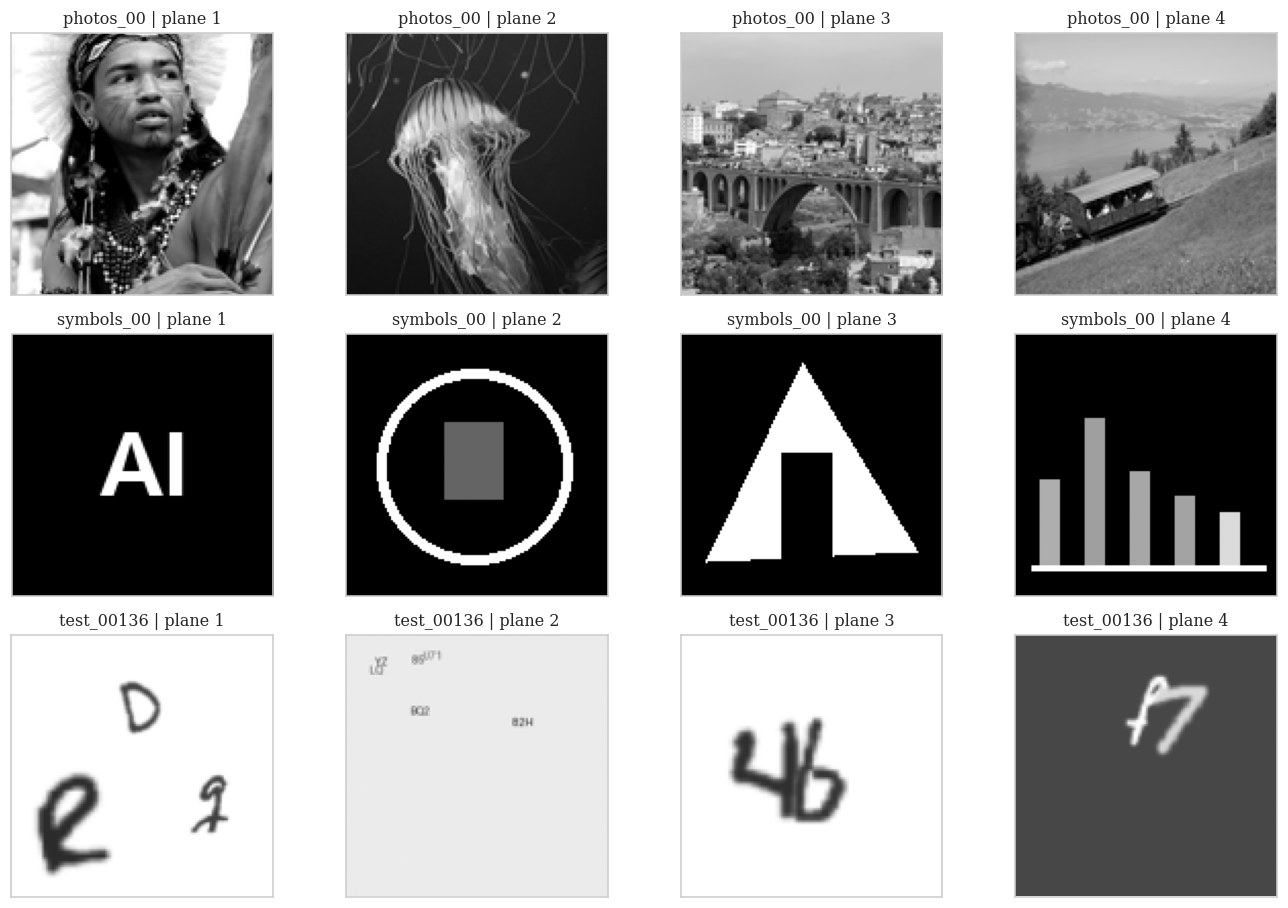

In [11]:
assert TARGETS.shape == (24,4,128,128) and TARGETS.dtype == np.uint8
metadata_frame = pd.DataFrame(CASE_METADATA)
display(metadata_frame.groupby(['source_set','composition']).size().rename('quartets').to_frame())
save_json(OUTPUT/'dataset_manifest.json',{'cases':CASE_METADATA,
    'targets_sha256':hashlib.sha256(TARGETS.tobytes()).hexdigest(),
    'normalization':'Per-plane maximum -> uint8 0..255; evaluation as normalized amplitude',
    'v3_selection_seed':20261107})
fig,axes=plt.subplots(3,4,figsize=(12,8))
for row,index in enumerate([0,4,12]):
    for plane in range(4):
        ax=axes[row,plane];ax.imshow(TARGETS[index,plane],cmap='gray',vmin=0,vmax=255)
        ax.set_title(f'{CASE_METADATA[index]["case"]} | plane {plane+1}',fontsize=10)
        ax.set_xticks([]);ax.set_yticks([]);ax.grid(False)
fig.tight_layout();publish_figure(fig,'target_examples',FIGURES)

### **3. Алгоритмы синтеза (Physics + Pretrained Inference)**

Сравниваются четыре режима:

| Метод | Как формируется маска |
| :--- | :--- |
| **GS ×300** | Начинаем со случайной фазы; переносим свет на экраны, подставляем целевую амплитуду и возвращаемся к маске. Выполняем 300 шагов. |
| **GS → Adam** | Получаем начальную маску через GS, затем меняем непосредственно её пиксели по ошибке четырёх восстановлений. Предварительный датасет не используется. |
| **DUSFN** | Готовая сеть предсказывает начальные фазы, выполняет обратное распространение и шесть последовательных физических шагов с обученными поправками. |
| **DUSFN → Adam** | Берём маску готовой сети и уточняем непосредственно её фазу под текущие четыре изображения. |

DUSFN содержит свёрточные и спектральные блоки; это развёрнутая физическая сеть, а не обычный U-Net. Используется исходная архитектура сохранённой модели, без добавления новых модулей.

Для двух режимов с Adam установлен одинаковый **общий бюджет 2 с на четвёрку**, включая инициализацию. У GS-режима начальный этап ограничен 300 шагами и доступным временем. Чистые GS ×300 и DUSFN показываются как отдельные ориентиры с фактическим временем. Прогрев выполнен заранее, порядок методов чередуется. Проверка времени каждые 10 шагов допускает небольшой выход за бюджет; он записывается в таблицу.

Во время уточнения минимизируется $(1-PCC)+(1-SSIM)$. Через каждые 10 шагов сохраняется лучший из проверенных вариантов по среднему $(PCC+SSIM)/2$ после квантования. Эта величина служит внутренним правилом выбора; PCC и SSIM в итогах публикуются отдельно.

*Веса DUSFN фиксированы. Они загружаются только в текущую среду и не включаются в ноутбук или экспортируемые результаты.*

In [12]:
checkpoint_path = locate_checkpoint()
network, checkpoint_info = load_frozen_network(checkpoint_path, DEVICE)
display(pd.DataFrame([{key:checkpoint_info[key] for key in
    ['model','selected_epoch','unroll_steps','real_parameter_components']}]))
del checkpoint_path

,model,selected_epoch,unroll_steps,real_parameter_components
0,DUSFN v3,11,6,75851990


In [13]:
results, summary, histories, reconstructions, total_seconds = compare_methods(
    TARGETS, CASE_METADATA, network, DEVICE, OUTPUT,
    seconds=BUDGET_SECONDS, seed=SEED)
manifest = {'run_id':RUN_ID,'seed':SEED,'torch':torch.__version__,'numpy':np.__version__,
    'device':torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'CPU',
    'python':platform.python_version(),'budget_seconds_per_hybrid':BUDGET_SECONDS,
    'cases':len(CASE_METADATA),'model':checkpoint_info,'physics_checks':physics_checks,
    'selection_rule':'Highest mean(PCC, SSIM) among evaluated checkpoints after phase/image quantization',
    'timing':'Initialization, solver and checkpoint evaluation included; warmup, load, I/O excluded',
    'wall_seconds':total_seconds,'weights_exported':False}
save_json(OUTPUT/'run_manifest.json',manifest)
print(f'[INFO] Total comparison time: {total_seconds:.1f} s')

[INFO] 01/24 | photos_00 | GS ×300      PCC=0.5615 | SSIM=0.3214 | 0.24 s
[INFO] 01/24 | photos_00 | GS → Adam    PCC=0.5752 | SSIM=0.4473 | 2.02 s
[INFO] 01/24 | photos_00 | DUSFN        PCC=0.4197 | SSIM=0.3036 | 0.02 s
[INFO] 01/24 | photos_00 | DUSFN → Adam PCC=0.5145 | SSIM=0.4469 | 2.01 s
[INFO] 02/24 | photos_01 | GS → Adam    PCC=0.5664 | SSIM=0.4692 | 2.01 s
[INFO] 02/24 | photos_01 | DUSFN        PCC=0.4278 | SSIM=0.3375 | 0.02 s
[INFO] 02/24 | photos_01 | DUSFN → Adam PCC=0.5331 | SSIM=0.4611 | 2.01 s
[INFO] 02/24 | photos_01 | GS ×300      PCC=0.4831 | SSIM=0.3579 | 0.17 s
[INFO] 03/24 | photos_02 | DUSFN        PCC=0.3903 | SSIM=0.3070 | 0.02 s
[INFO] 03/24 | photos_02 | DUSFN → Adam PCC=0.5168 | SSIM=0.4441 | 2.01 s
[INFO] 03/24 | photos_02 | GS ×300      PCC=0.5103 | SSIM=0.3513 | 0.17 s
[INFO] 03/24 | photos_02 | GS → Adam    PCC=0.5459 | SSIM=0.4489 | 2.04 s
[INFO] 04/24 | photos_03 | DUSFN → Adam PCC=0.5144 | SSIM=0.4572 | 2.01 s
[INFO] 04/24 | photos_03 | GS ×300    

### **4. Метрики и Время вычисления**

**PCC** оценивает совпадение пространственного рисунка, **SSIM** — локальной структуры изображения. Для SSIM используется гауссово окно $11\times11$, $\sigma=1.5$, диапазон [0,1] и только область полного окна. Дополнительно сохраняется качество худшей из четырёх плоскостей.

В таблице приведены новые результаты текущего запуска. Строки `diagnostic12` и `v3_stratified12` относятся к разным частям набора; `ALL` — их описательное среднее с одинаковым весом каждой четвёрки. Время зависит от выбранного ускорителя.

,source_set,method,PCC,SSIM,worst_PCC,worst_SSIM,seconds
0,ALL,DUSFN,0.4515,0.3411,0.2428,0.2536,0.0207
1,ALL,DUSFN_Adam,0.5211,0.4730,0.3269,0.3399,2.0190
2,ALL,GS300,0.5231,0.2394,0.3131,0.1690,0.1752
3,ALL,GS_Adam,0.5602,0.4156,0.3526,0.2789,2.0221
4,diagnostic12,DUSFN,0.4797,0.2882,0.2877,0.2341,0.0207
5,diagnostic12,DUSFN_Adam,0.5496,0.4051,0.3581,0.3078,2.0189
6,diagnostic12,GS300,0.5736,0.2299,0.3797,0.1717,0.1794
7,diagnostic12,GS_Adam,0.5707,0.4154,0.3533,0.3025,2.0198
8,v3_stratified12,DUSFN,0.4234,0.3939,0.1978,0.2731,0.0206
9,v3_stratified12,DUSFN_Adam,0.4926,0.5409,0.2957,0.3721,2.0192


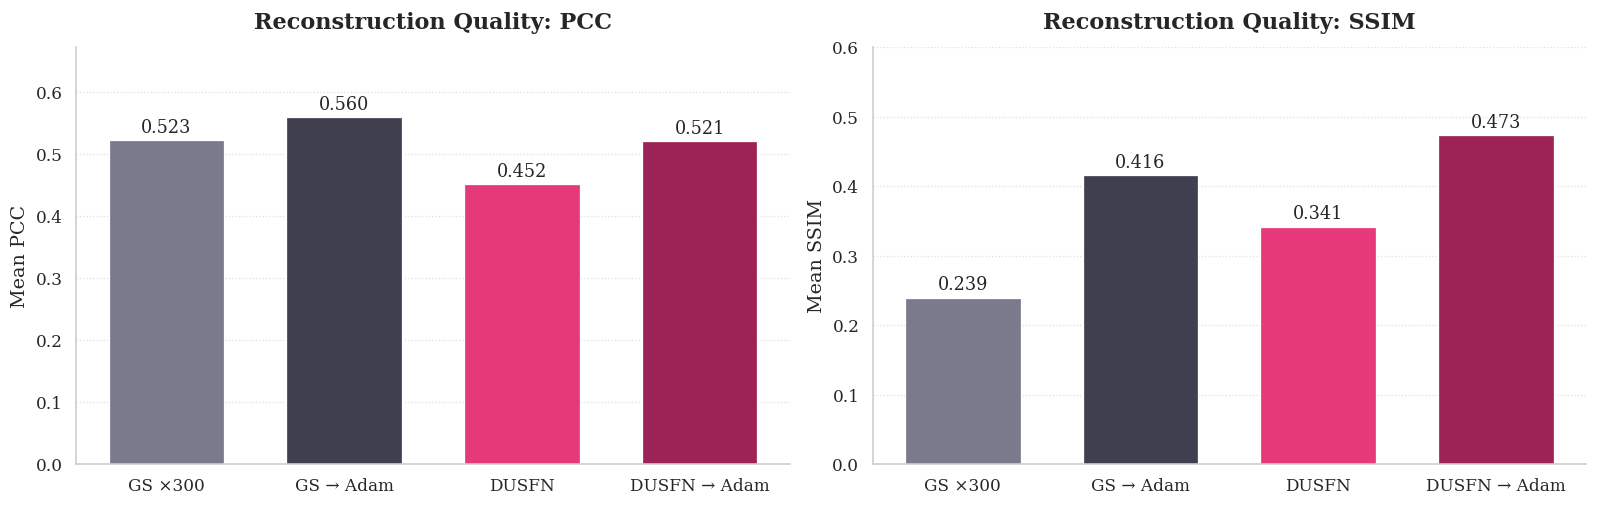

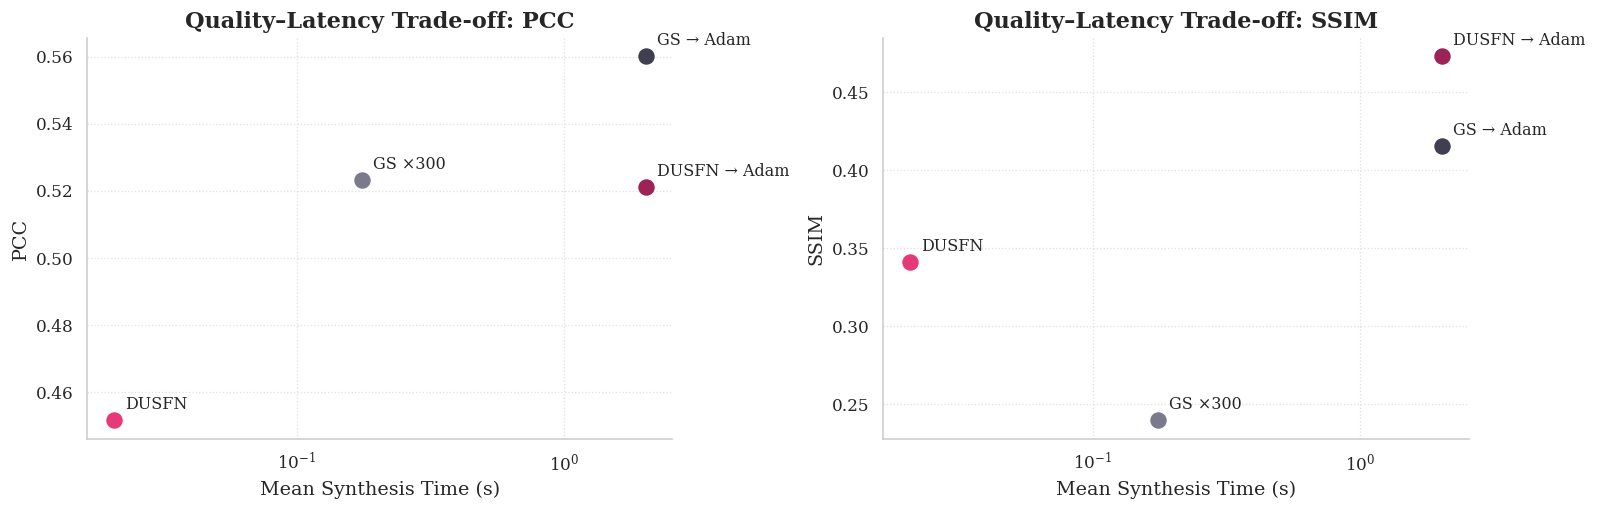

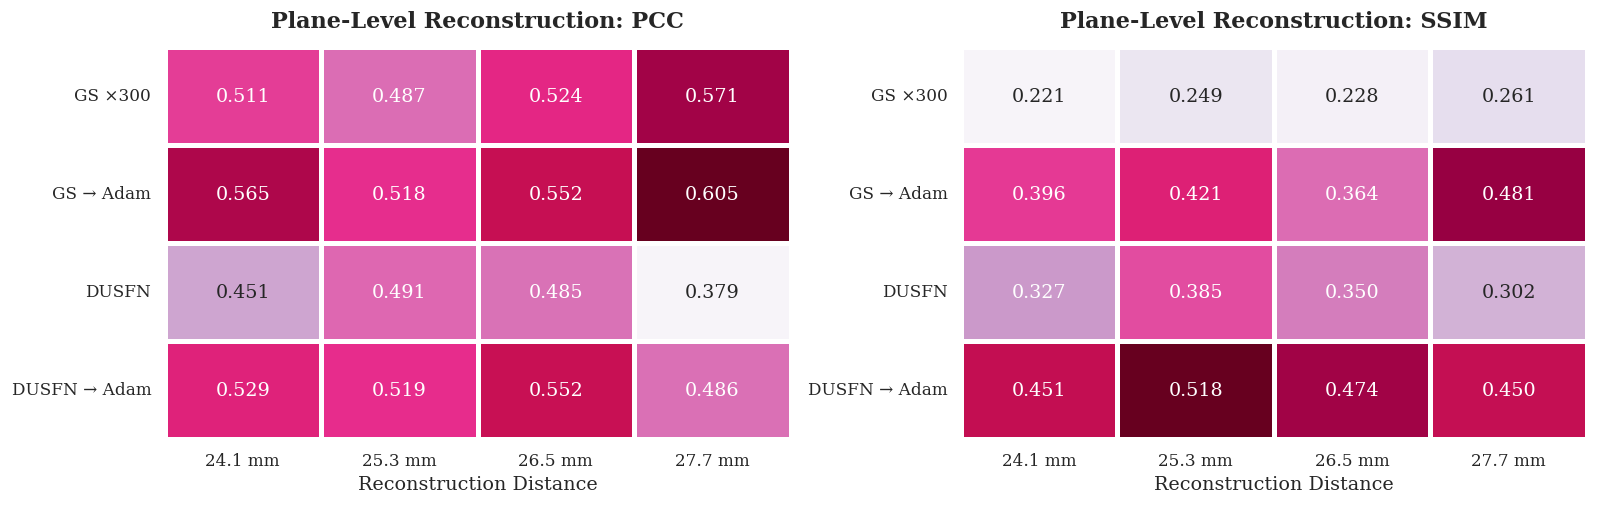

[INFO] Maximum timing overrun: 0.0413 s


In [14]:
display(summary.round(4))
plot_metric_dashboard(results,FIGURES)
plot_plane_metrics(results,FIGURES)
print('[INFO] Maximum timing overrun:',round(results.overrun_seconds.max(),4),'s')

### **5. Визуальная оценка восстановления**

Для фиксированных примеров показываются исходные четыре цели и результаты каждого метода. Все изображения отображаются в одной шкале [0,255]; подписи содержат метрики соответствующей плоскости.

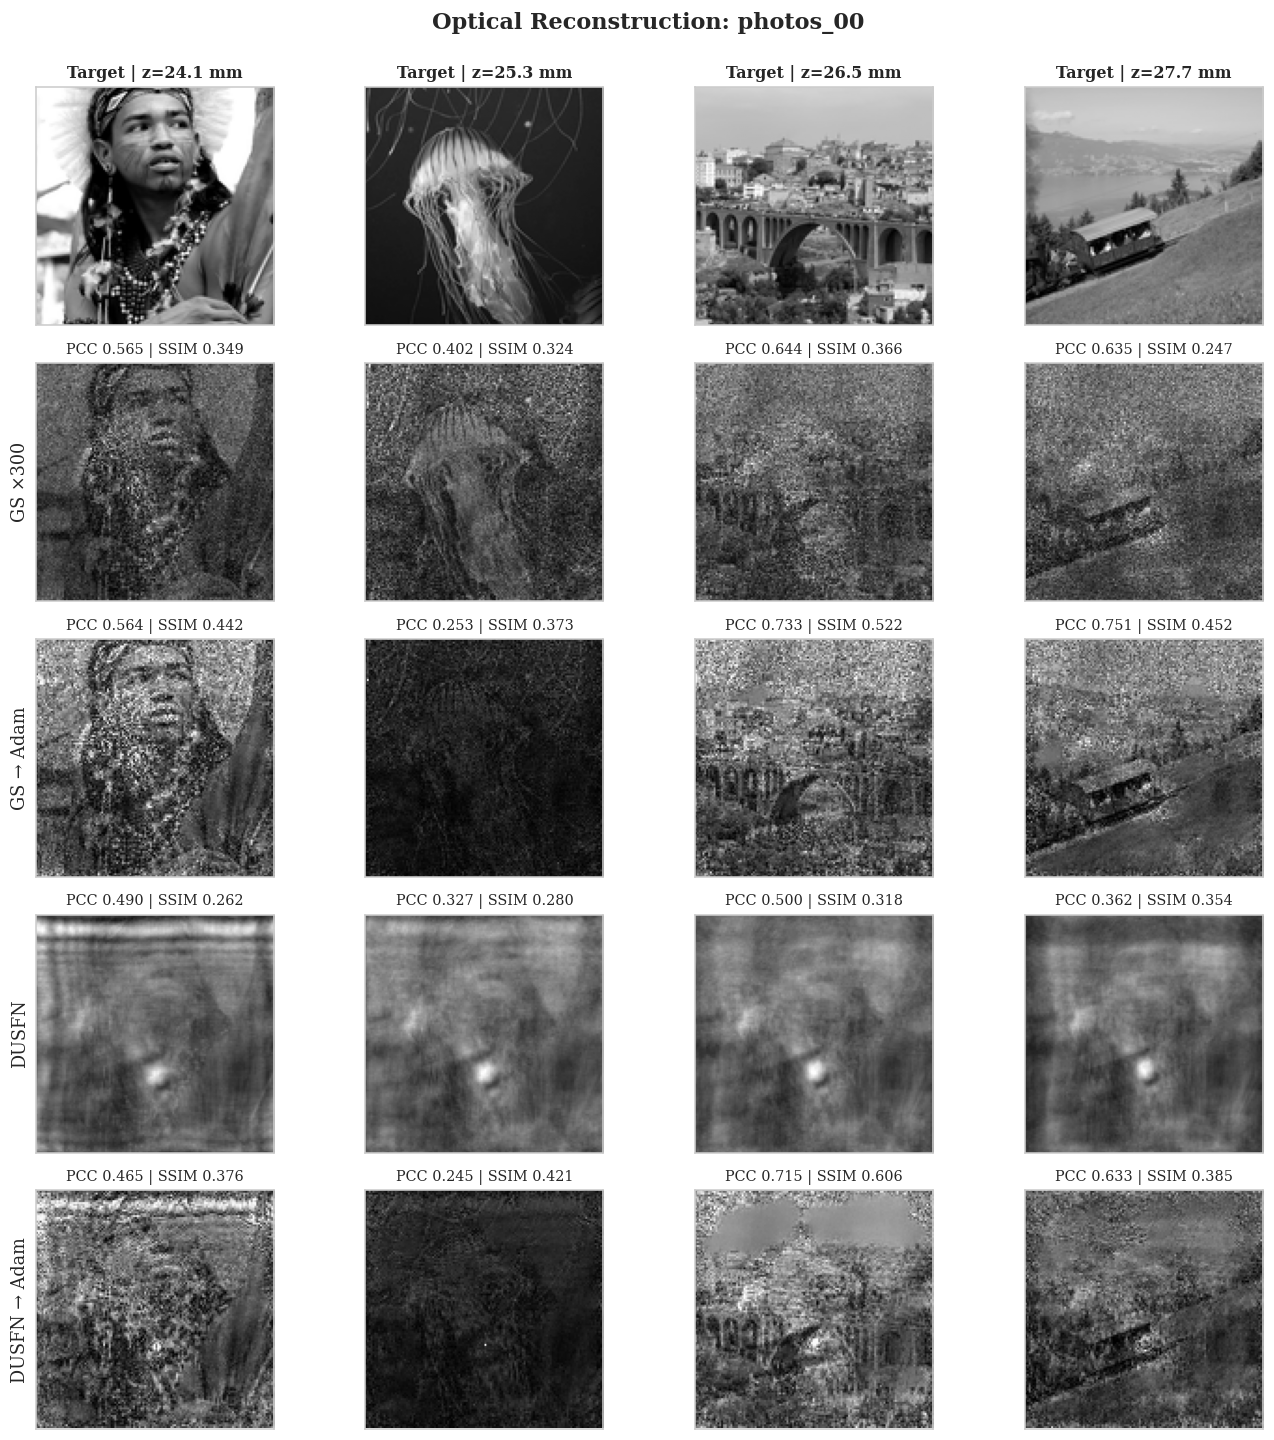

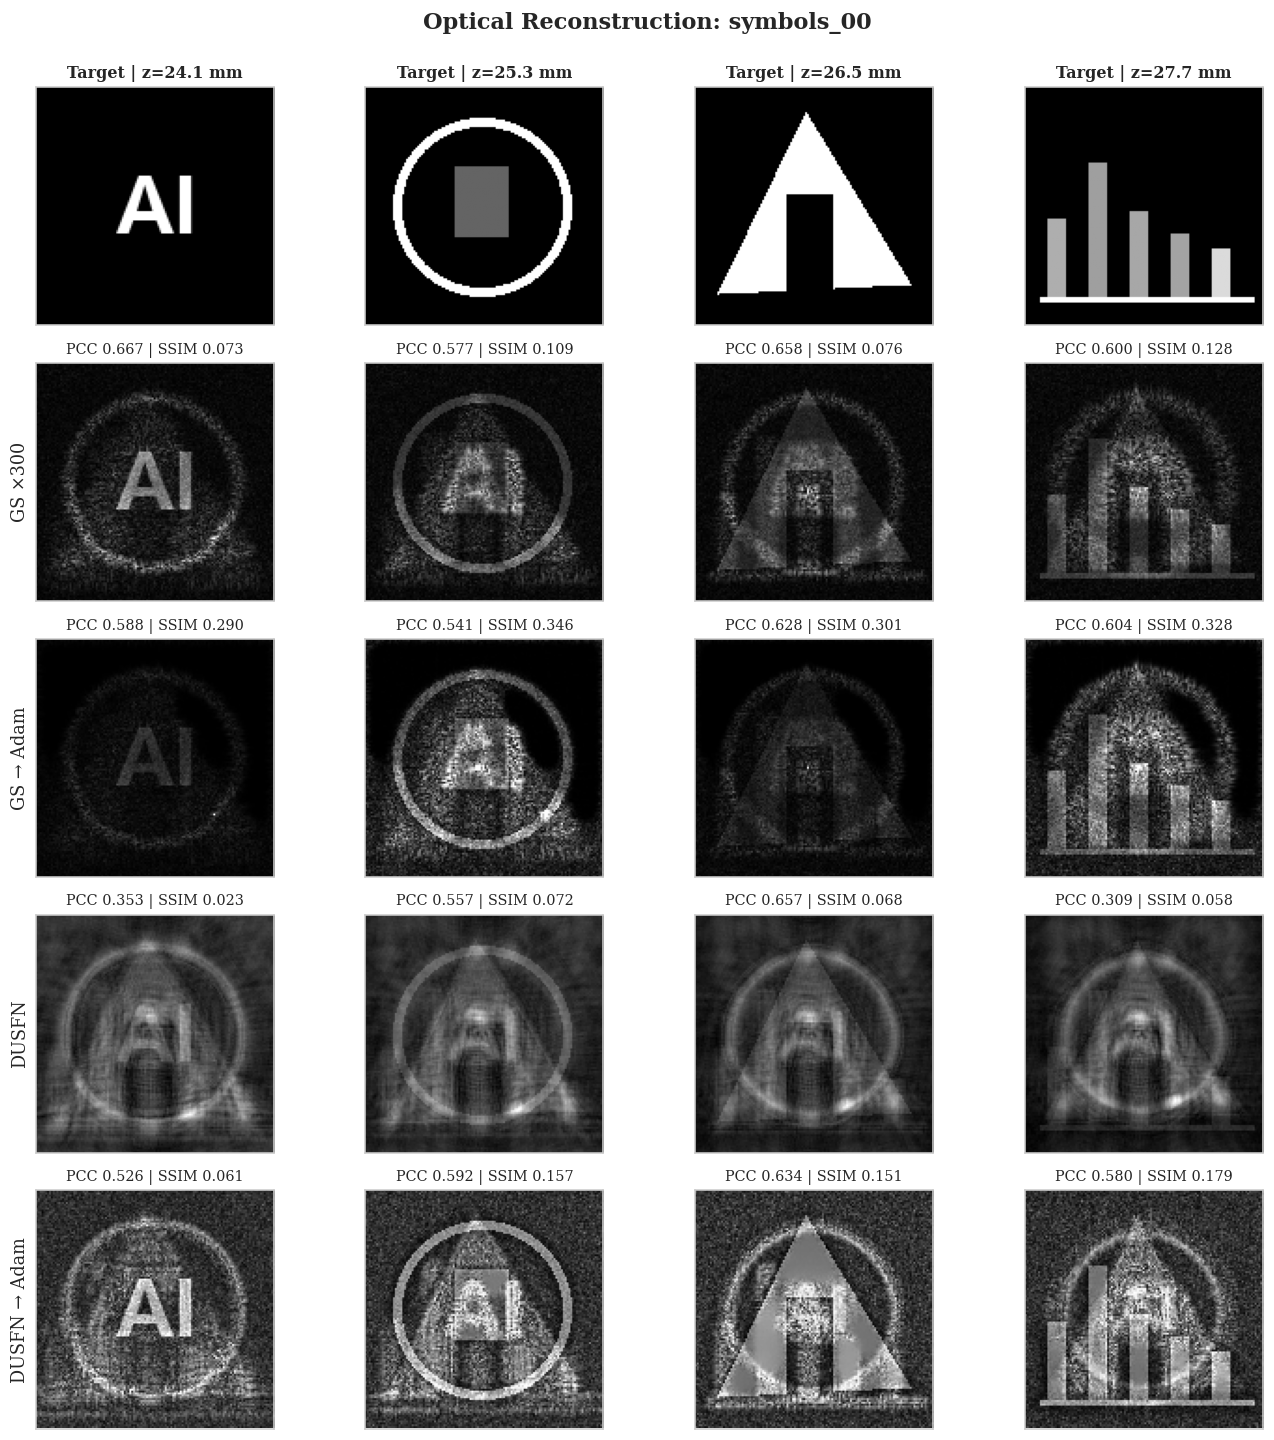

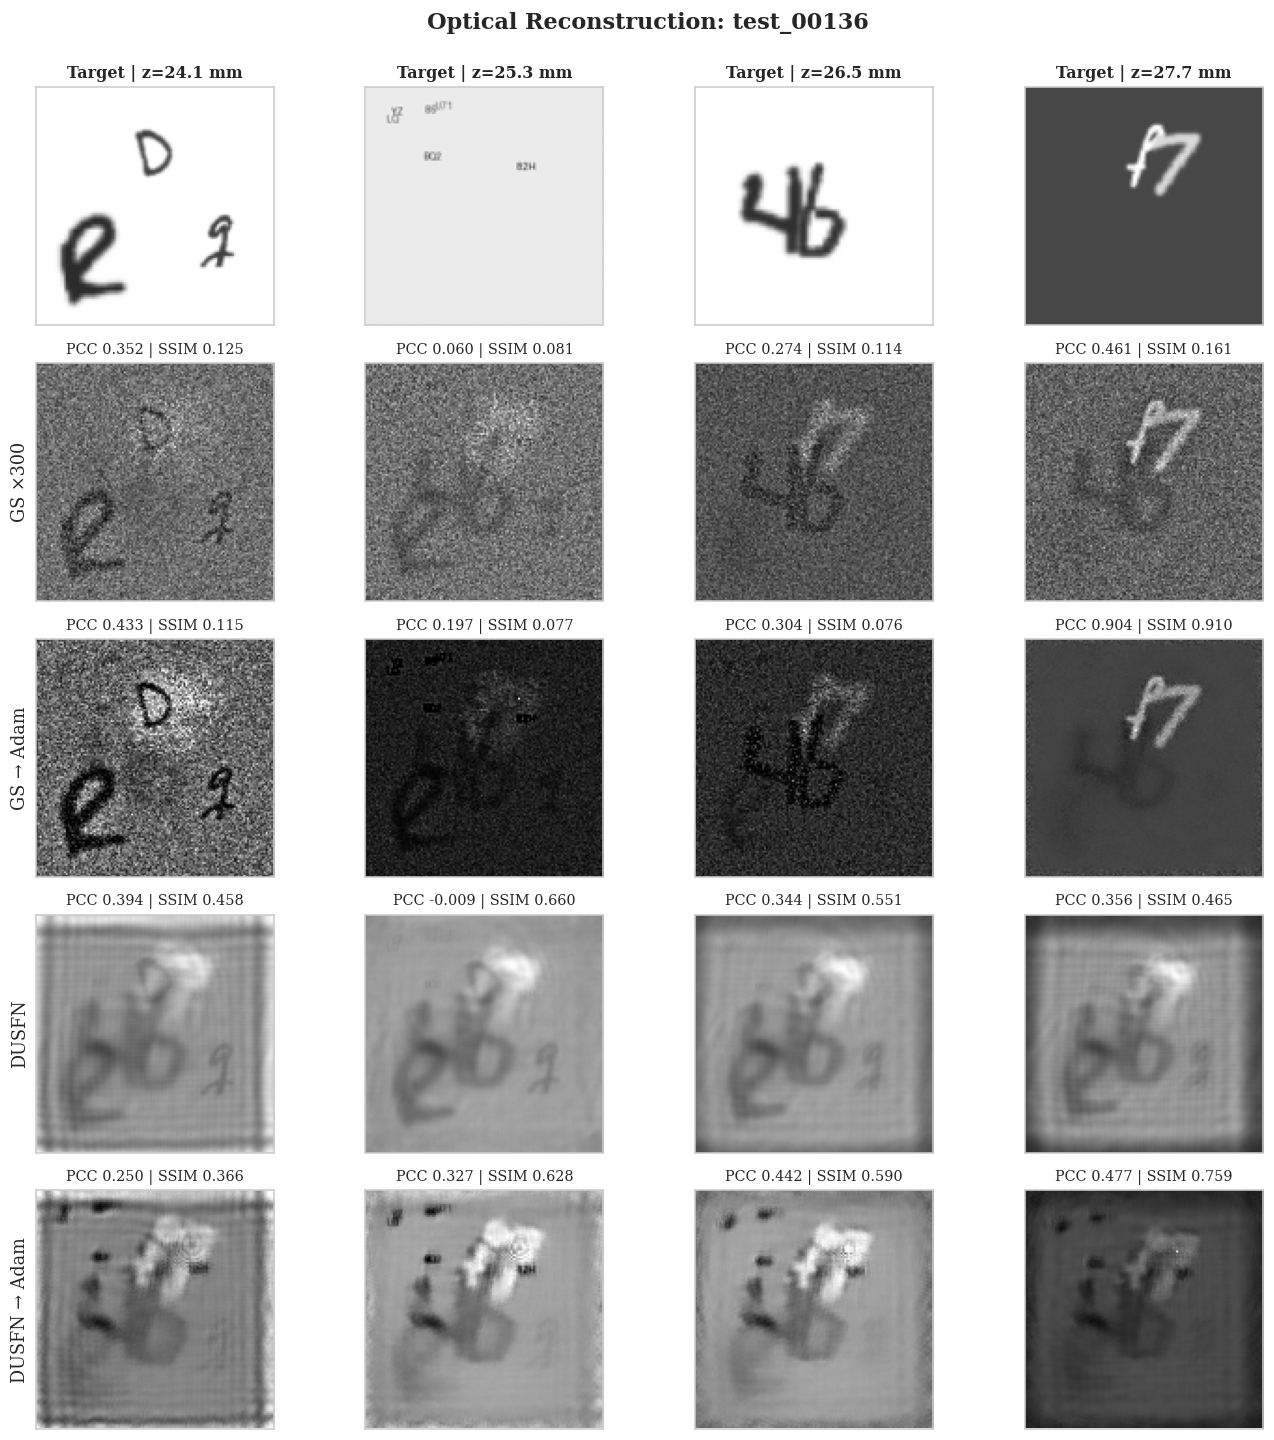

In [15]:
for index in [0,4,12]:
    plot_reconstruction(index,TARGETS,CASE_METADATA,results,reconstructions,FIGURES)

### **6. Inference Pipeline (Практическое применение)**

Функция `build_hologram` принимает четыре изображения размером $128\times128$, нормирует их, строит маску выбранным методом и сохраняет `doe.png`, четыре восстановления и таблицу качества. Режим `GS_Adam` не обращается к сети; для режимов DUSFN используются уже загруженные веса.

Ниже выполнен один дополнительный запуск на тестовой четвёрке. Для своих изображений достаточно передать список из четырёх путей или массив формы `(4,128,128)`.

In [16]:
def build_hologram(images, method='GS_Adam', seconds=BUDGET_SECONDS, output=None):
    if method not in METHODS:
        raise ValueError(f'Доступные методы: {METHODS}')
    if isinstance(images,(list,tuple)) and all(isinstance(p,(str,Path)) for p in images):
        arrays=[np.asarray(PILImage.open(p).convert('L')).copy() for p in images]
        raw=np.stack(arrays).astype(np.float32)
    else:
        raw=np.asarray(images,dtype=np.float32)
    if raw.shape!=(4,128,128) or not np.isfinite(raw).all() or raw.min()<0:
        raise ValueError('Ожидаются четыре неотрицательных изображения 128×128.')
    if np.any(raw.max(axis=(-2,-1))<=0):
        raise ValueError('Полностью чёрные целевые плоскости требуют отдельного протокола оценки.')
    normalized=np.rint(raw/raw.max(axis=(-2,-1),keepdims=True)*255).astype(np.uint8)
    target=torch.from_numpy(normalized.astype(np.float32)/255).to(DEVICE)
    solution=optimize_one(target,method,network,Fresnel().to(DEVICE),seconds=seconds,seed=SEED)
    folder=Path(output) if output is not None else OUTPUT/'inference_demo'
    metrics,reconstruction=export_solution(solution,normalized,Fresnel(),folder)
    return folder,metrics,reconstruction

demo_folder,demo_metrics,_=build_hologram(TARGETS[0])
print('[INFO] Saved:',demo_folder.name+'/doe.png')
display(pd.DataFrame([{'PCC':demo_metrics['pcc'],'SSIM':demo_metrics['ssim']}]).round(4))

[INFO] Saved: inference_demo/doe.png


,PCC,SSIM
0,0.5752,0.4498


### **7. Экспорт результатов**

Сопоставление с историческими экспериментами и описание использованных смесей данных приведены в `02_data_and_experiments.ipynb`.

In [17]:
archive_path=export_public_results(OUTPUT)
offer_download(archive_path)

[INFO] Results: photonic_solution_20261107_204741.zip | 12.3 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>